# 01 · Visium: download, QC, label maps

Public Visium with expert TLS annotation: **GEO GSE175540** (Meylan et al., Immunity 2022; ccRCC; 23 annotated sections, FFPE + frozen) and **Zenodo 14620362** (USZ; 8 FFPE sections, kidney + lung, CC-BY-4.0; spot maturity ETLS / MTLS / GC).

Idempotent: files already on disk are skipped. Output: one AnnData per section in `data/visium/h5ad/`.

In [1]:
import logging, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
(ROOT / "results").mkdir(exist_ok=True)
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s %(message)s",
                    handlers=[logging.StreamHandler(sys.stdout), logging.FileHandler(ROOT / "results" / "notebooks.log")],
                    force=True)
for noisy in ("anndata", "fsspec", "matplotlib", "PIL"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tls_model import pipeline
cfg = pipeline.load_config()
paths = {k: ROOT / v for k, v in cfg["paths"].items()}
FIG = paths["results"] / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Download + per-section AnnData

In [2]:
from tls_model import io_visium

failed = io_visium.download_all(paths["visium_raw"])
failed += io_visium.build_h5ad(paths["visium_raw"], paths["visium_h5ad"])
assert not failed, failed
print(len(list(paths["visium_h5ad"].glob("*.h5ad"))), "sections")

2026-10-08 21:46:13,222 INFO tls_model.io_visium [1/117] SKIP gse175540\bulk_TPM.csv.gz


2026-10-08 21:46:13,768 INFO tls_model.io_visium [2/117] SKIP gse175540\ffpe_c_2\filtered_feature_bc_matrix.h5


2026-10-08 21:46:14,302 INFO tls_model.io_visium [3/117] SKIP gse175540\ffpe_c_2\tissue_positions_list.csv.gz


2026-10-08 21:46:14,817 INFO tls_model.io_visium [4/117] SKIP gse175540\ffpe_c_2\scalefactors_json.json.gz


2026-10-08 21:46:15,374 INFO tls_model.io_visium [5/117] SKIP gse175540\ffpe_c_2\tissue_lowres_image.png.gz


...

2026-10-08 21:47:13,952 INFO tls_model.io_visium [28/31] SKIP USZ_LC2


2026-10-08 21:47:13,954 INFO tls_model.io_visium [29/31] SKIP USZ_LC3


2026-10-08 21:47:13,955 INFO tls_model.io_visium [30/31] SKIP USZ_LC4


2026-10-08 21:47:13,955 INFO tls_model.io_visium [31/31] SKIP USZ_LC5


31 sections


## QC table

In [3]:
import anndata as ad

rows, sections = [], {}
for path in sorted(paths["visium_h5ad"].glob("*.h5ad")):
    a = ad.read_h5ad(path)
    sections[path.stem] = a
    umi = np.asarray(a.X.sum(axis=1)).ravel()
    n_genes = np.asarray((a.X > 0).sum(axis=1)).ravel()
    rows.append({
        "section": path.stem, "source": a.obs["source"].iloc[0], "protocol": a.obs["protocol"].iloc[0],
        "patient": a.obs["patient"].iloc[0], "spots": a.n_obs, "genes": a.n_vars,
        "median_umi": int(np.median(umi)), "median_genes": int(np.median(n_genes)),
        "tls_spots": int(a.obs["tls"].sum()), "tls_share": round(a.obs["tls"].mean(), 3),
        "mature_spots": int((a.obs["tls_mature"] == 1).sum()), "immature_spots": int((a.obs["tls_mature"] == 0).sum()),
        "excluded_LN": int(a.obs["excluded"].sum()),
        "labels": ", ".join(f"{k}:{v}" for k, v in a.obs["label_raw"].astype(str).replace("", "unassigned").value_counts().items()),
    })
qc = pd.DataFrame(rows)
qc.to_csv(paths["results"] / "visium_qc.tsv", sep="\t", index=False)
qc

,section,source,protocol,patient,spots,genes,median_umi,median_genes,tls_spots,tls_share,mature_spots,immature_spots,excluded_LN,labels
0,ffpe_c_2,GSE175540,ffpe,GSE175540_c_2,4510,17943,5120,2870,131,0.029,0,0,0,"NO_TLS:4378, TLS:131, unassigned:1"
1,ffpe_c_20,GSE175540,ffpe,GSE175540_c_20,4948,17943,3554,2371,102,0.021,0,0,0,"NO_TLS:4846, TLS:102"
2,ffpe_c_21,GSE175540,ffpe,GSE175540_c_21,4915,17943,13010,4815,0,0.000,0,0,0,NO_TLS:4915
3,ffpe_c_3,GSE175540,ffpe,GSE175540_c_3,4755,17943,16459,5515,257,0.054,0,0,0,"NO_TLS:4498, TLS:257"
4,ffpe_c_34,GSE175540,ffpe,GSE175540_c_34,3585,17943,4576,2429,88,0.025,0,0,0,"NO_TLS:3497, TLS:88"
5,ffpe_c_36,GSE175540,ffpe,GSE175540_c_36,3206,17943,7685,3909,255,0.080,0,0,0,"NO_TLS:2951, TLS:255"
6,ffpe_c_39,GSE175540,ffpe,GSE175540_c_39,4940,17943,7161,3603,16,0.003,0,0,0,"NO_TLS:4924, TLS:16"
7,ffpe_c_4,GSE175540,ffpe,GSE175540_c_4,3829,17943,9719,4513,199,0.052,0,0,0,"NO_TLS:3607, TLS:199, unassigned:23"
8,ffpe_c_45,GSE175540,ffpe,GSE175540_c_45,4562,17943,6476,3584,21,0.005,0,0,0,"NO_TLS:4541, TLS:21"
9,ffpe_c_51,GSE175540,ffpe,GSE175540_c_51,4359,17943,7971,3852,206,0.047,0,0,0,"NO_TLS:4153, TLS:206"


In [4]:
print(qc.groupby(["source", "protocol"])[["spots", "tls_spots", "mature_spots", "immature_spots"]].sum())
print("patients:", qc["patient"].nunique())

                    spots  tls_spots  mature_spots  immature_spots
source    protocol                                                
GSE175540 ffpe      48584       1403             0               0
          frozen    20776        921             0               0
USZ       ffpe      24246        925           396             529
patients: 30


## Label maps (array coordinates)

Red = TLS spot, black = hard negative (T_agg / INFL), grey = other.

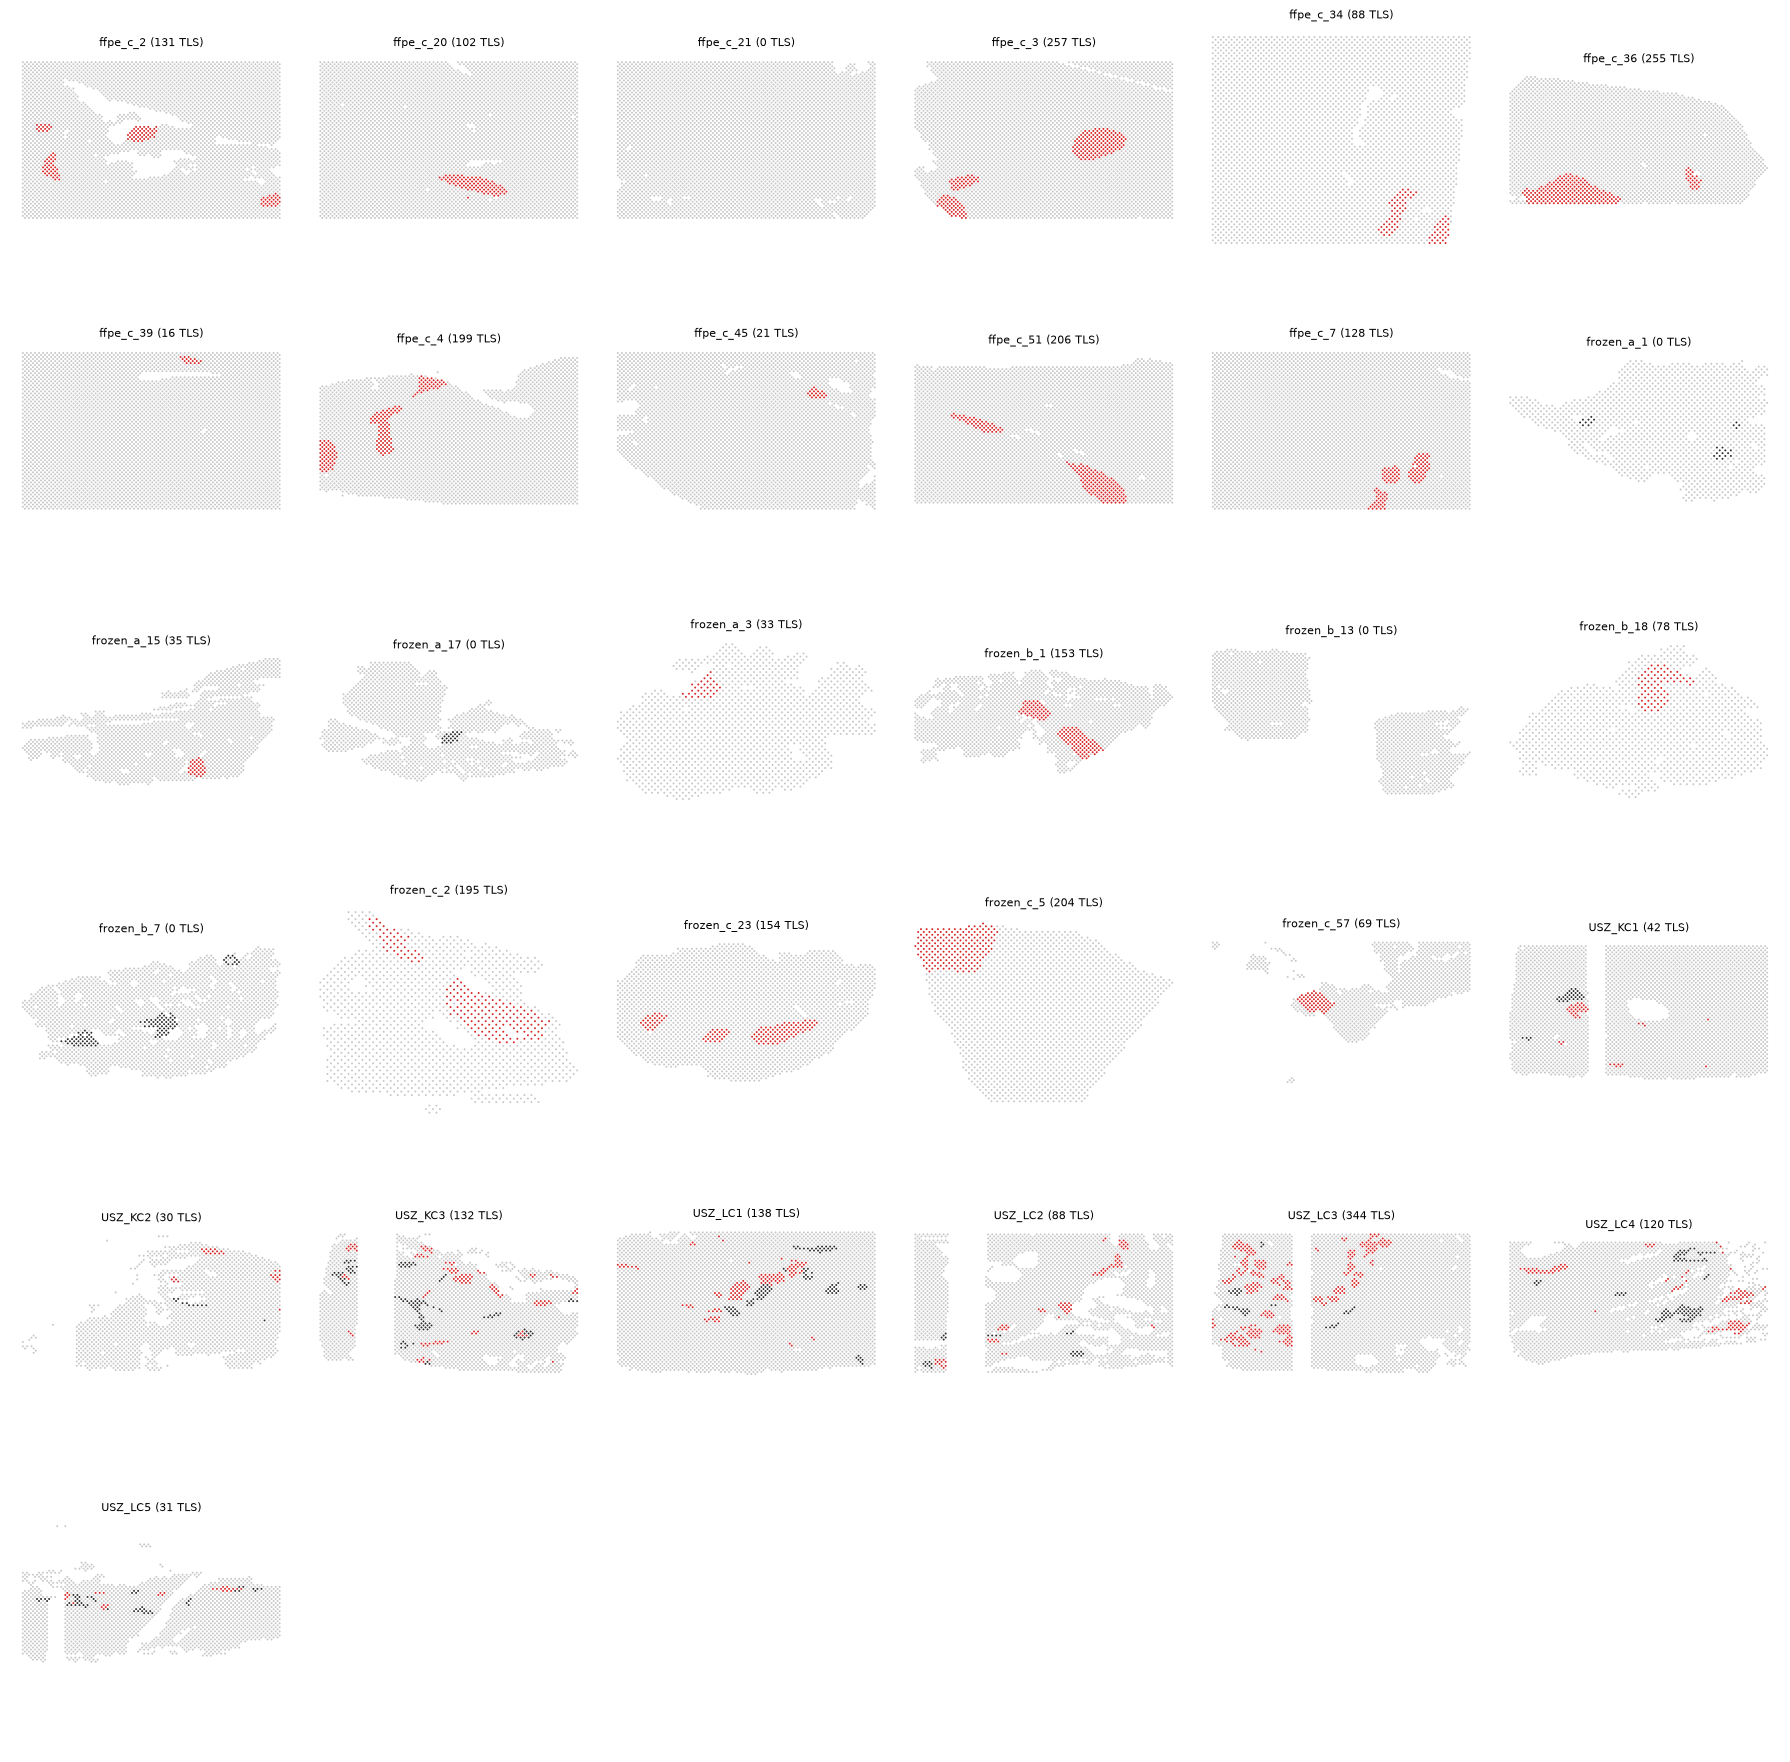

In [5]:
def label_colour(obs):
    raw = obs["label_raw"].astype(str)
    colour = np.where(obs["tls"] == 1, "#d62728", "#c7c7c7")
    return np.where(raw.isin(["T_agg", "INFL"]), "#2b2b2b", colour)

names = list(sections)
n_cols = 6
n_rows = int(np.ceil(len(names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
for ax, name in zip(axes.ravel(), names):
    obs = sections[name].obs
    ax.scatter(obs["array_col"], -obs["array_row"], c=label_colour(obs), s=2, linewidths=0)
    ax.set_title(f"{name} ({int(obs['tls'].sum())} TLS)", fontsize=8)
    ax.set_aspect("equal"); ax.axis("off")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "01_label_maps.png", dpi=120)

## Labels on H&E (GSE175540 low-res image)

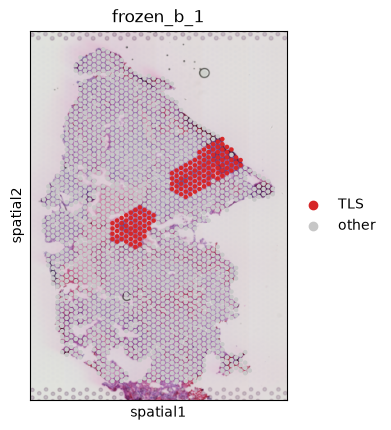

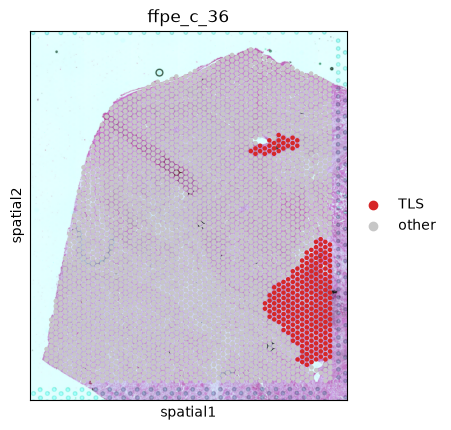

In [6]:
import scanpy as sc

for name in ("frozen_b_1", "ffpe_c_36"):
    a = sections[name].copy()
    a.obs["label"] = pd.Categorical(np.where(a.obs["tls"] == 1, "TLS", np.where(a.obs["label_raw"] == "T_agg", "T_agg", "other")))
    sc.pl.spatial(a, color="label", library_id=name, img_key="lowres", size=1.3,
                  palette={"TLS": "#d62728", "T_agg": "#1f1f1f", "other": "#c7c7c7"}, title=name, show=True)